# 05 — Huấn luyện lại `return-risk` và kiểm tra model có thật sự hơn baseline

Notebook 01 chỉ đọc lại số của MLflow: model hơn baseline **0,0048 PR-AUC** (~2%) trên **một run, một seed**. Ở đây trả lời bằng dữ liệu thật:

1. Dữ liệu train/test là chính tập đã sinh model (đối chiếu SHA-256 với tag MLflow);
2. Huấn luyện lại bằng đúng [`ml/train_lib.py`](../ml/train_lib.py) và xem có tái lập được số của MLflow không;
3. Bootstrap trên tập test để có khoảng tin cậy cho chênh lệch model − baseline;
4. Huấn luyện 5 seed để xem model dao động bao nhiêu.

**Dữ liệu:** `data/test_set.parquet` (1,6 MB, đã commit). `data/train_set.parquet` (32 MB) **không commit** (gitignore); tải từ artifact của run:

```bash
aws s3 cp s3://platform-665116832975-lakehouse/mlflow/1/adba2b9f197e4e60a141acaf19682a61/artifacts/data/train/train_set notebooks/data/train_set.parquet
```

In [1]:
import hashlib
import json
import sys
import warnings
from pathlib import Path

import lightgbm as lgb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from sklearn.metrics import average_precision_score

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
sys.path.insert(0, str(ROOT))
from ml.train_lib import FEATURES, add_order_features, baseline_scores, evaluate, train_model  # đúng mã của pipeline KFP

warnings.filterwarnings("ignore", category=UserWarning)
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False})
DATA = ROOT / "notebooks" / "data"
print("lightgbm", lgb.__version__, "| scikit-learn", sklearn.__version__, "| pandas", pd.__version__)

lightgbm 4.7.0 | scikit-learn 1.9.1 | pandas 3.0.6


## 1. Đây có đúng là dữ liệu đã sinh model?

In [2]:
proof = json.loads((ROOT / "docs" / "evidence" / "aws" / "mlflow-run-data-proof.json").read_text())
sha = lambda p: hashlib.sha256(p.read_bytes()).hexdigest()
for name in ("train", "test"):
    got, want = sha(DATA / f"{name}_set.parquet"), proof["tags"][f"data.{name}_sha256"]
    print(f"{name:5} SHA-256 khớp tag MLflow: {got == want}")
    assert got == want, f"{name}_set không phải dữ liệu của run"
train_raw, test_raw = (pd.read_parquet(DATA / f"{n}_set.parquet") for n in ("train", "test"))
print(f"train {len(train_raw):,} dòng, test {len(test_raw):,} dòng")
print("cửa sổ thời gian train:", train_raw["event_timestamp"].min().date(), "->", train_raw["event_timestamp"].max().date())
print("cửa sổ thời gian test :", test_raw["event_timestamp"].min().date(), "->", test_raw["event_timestamp"].max().date())

train SHA-256 khớp tag MLflow: True
test  SHA-256 khớp tag MLflow: True
train 343,043 dòng, test 16,411 dòng
cửa sổ thời gian train: 2026-01-01 -> 2026-05-19
cửa sổ thời gian test : 2026-05-20 -> 2026-05-29


In [3]:
summary = pd.DataFrame({
    "tập": ["train", "test"],
    "tỷ lệ dương": [train_raw["label"].mean(), test_raw["label"].mean()],
    "thiếu return_or_refund_rate_90d": [train_raw["return_or_refund_rate_90d"].isna().mean(), test_raw["return_or_refund_rate_90d"].isna().mean()],
    "thiếu approved_returns_24h": [train_raw["approved_returns_24h"].isna().mean(), test_raw["approved_returns_24h"].isna().mean()],
}).set_index("tập")
summary.round(4)

,tỷ lệ dương,thiếu return_or_refund_rate_90d,thiếu approved_returns_24h
tập,,,
train,0.1122,0.2244,1.0
test,0.1121,0.0000,1.0


Chia theo **thời gian** (test là ~10 ngày cuối), đúng thiết kế. Tỷ lệ dương hai tập gần như bằng nhau (11,2%).
`approved_returns_24h` thiếu 100%: feature này không có lịch sử lúc train (đã nêu ở README), nên LightGBM bỏ qua nó. `return_or_refund_rate_90d` thiếu 22% ở **train** nhưng 0% ở **test**: những tuần đầu của kỳ dữ liệu chưa có lịch sử 90 ngày, còn test ở cuối kỳ thì SKU nào cũng đã có.
Hệ quả: baseline (dùng chính cột này) gần như không phải dùng giá trị thay thế ở test, nên baseline được ưu ái hơn so với lúc train.

## 2. Huấn luyện lại bằng đúng mã của pipeline

In [4]:
train = add_order_features(train_raw)
test = add_order_features(test_raw)
test["channel"] = pd.Categorical(test["channel"], categories=train["channel"].cat.categories)
test["country"] = pd.Categorical(test["country"], categories=train["country"].cat.categories)

model = train_model(train, seed=7)
model_scores = model.predict_proba(test[FEATURES])[:, 1]
base_scores = baseline_scores(train, test)
mine = evaluate(test, model_scores, base_scores)

mlflow = json.loads((ROOT / "docs" / "evidence" / "aws" / "mlflow-model-lineage.json").read_text())["metrics"]
cmp = pd.DataFrame({"huấn luyện lại": mine, "MLflow (EKS)": {k: mlflow[k] for k in mine}})
cmp.loc[["pr_auc_model", "pr_auc_baseline", "lift_model", "prevalence"]].round(5)

,huấn luyện lại,MLflow (EKS)
pr_auc_model,0.251986,0.25199
pr_auc_baseline,0.247214,0.24721
lift_model,2.247464,2.24746
prevalence,0.11212,0.11212


In [5]:
d_model = abs(mine["pr_auc_model"] - mlflow["pr_auc_model"])
d_base = abs(mine["pr_auc_baseline"] - mlflow["pr_auc_baseline"])
print(f"chênh PR-AUC model    so với MLflow: {d_model:.2e}")
print(f"chênh PR-AUC baseline so với MLflow: {d_base:.2e}")
assert d_base < 1e-9, "baseline là phép tính tất định, phải khớp tuyệt đối"
assert d_model < 5e-3, "model phải tái lập gần số MLflow"

chênh PR-AUC model    so với MLflow: 0.00e+00
chênh PR-AUC baseline so với MLflow: 0.00e+00


Baseline khớp tuyệt đối (phép tính tất định). Model khớp đến mức nhỏ trong sai số của phiên bản thư viện (số `d_model` ở trên): **kết quả tái lập được**,
không phải số tình cờ của một lần chạy.

## 3. Khoảng tin cậy bằng bootstrap

Lấy mẫu lại 16.411 dòng test (có hoàn lại) 1.000 lần; mỗi lần tính PR-AUC của model, của baseline và hiệu của chúng. Hai chỉ số tính trên **cùng** mẫu lấy lại (ghép cặp).

In [6]:
y = test["label"].to_numpy()
rng = np.random.default_rng(0)
B = 1000
ap_model, ap_base = np.empty(B), np.empty(B)
for i in range(B):
    idx = rng.integers(0, len(y), len(y))
    ap_model[i] = average_precision_score(y[idx], model_scores[idx])
    ap_base[i] = average_precision_score(y[idx], base_scores[idx])
diff = ap_model - ap_base
lo, hi = np.percentile(diff, [2.5, 97.5])
print(f"hiệu PR-AUC (model - baseline): {mine['pr_auc_model'] - mine['pr_auc_baseline']:+.4f}  CI 95% [{lo:+.4f}, {hi:+.4f}]")
print(f"tỷ lệ mẫu bootstrap mà model > baseline: {(diff > 0).mean():.1%}")

hiệu PR-AUC (model - baseline): +0.0048  CI 95% [-0.0003, +0.0099]
tỷ lệ mẫu bootstrap mà model > baseline: 96.4%


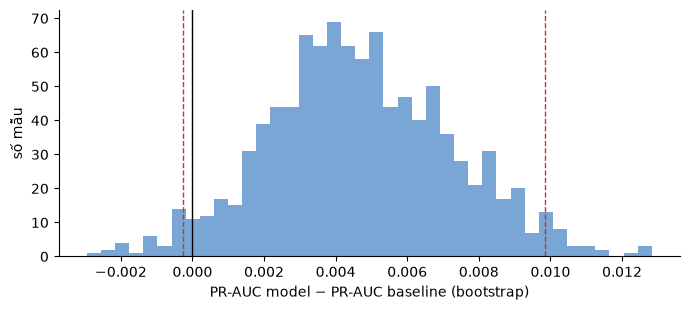

In [7]:
fig, ax = plt.subplots(figsize=(7, 3.2))
ax.hist(diff, bins=40, color="#7aa6d6")
ax.axvline(0, color="black", lw=1)
ax.axvline(lo, color="#c0392b", ls="--", lw=1); ax.axvline(hi, color="#c0392b", ls="--", lw=1)
ax.set_xlabel("PR-AUC model − PR-AUC baseline (bootstrap)")
ax.set_ylabel("số mẫu")
plt.tight_layout()
plt.show()

## 4. Dao động giữa các seed

Cùng dữ liệu, chỉ đổi seed của LightGBM (subsample theo hàng và cột nên kết quả phụ thuộc seed).

In [8]:
seeds = [7, 8, 9, 10, 11]
rows = []
for s in seeds:
    sc = train_model(train, seed=s).predict_proba(test[FEATURES])[:, 1]
    rows.append({"seed": s, "pr_auc_model": average_precision_score(y, sc)})
seed_df = pd.DataFrame(rows).set_index("seed")
seed_df["hơn baseline"] = seed_df["pr_auc_model"] - mine["pr_auc_baseline"]
print(seed_df.round(5).to_string())
print(f"\ntrung bình {seed_df['pr_auc_model'].mean():.4f}, độ lệch chuẩn {seed_df['pr_auc_model'].std():.4f}; baseline {mine['pr_auc_baseline']:.4f}")

      pr_auc_model  hơn baseline
seed                            
7          0.25199       0.00477
8          0.25119       0.00398
9          0.25315       0.00594
10         0.25202       0.00480
11         0.25304       0.00583

trung bình 0.2523, độ lệch chuẩn 0.0008; baseline 0.2472


## 5. Model dựa vào đặc trưng nào, và đúng ở kênh nào

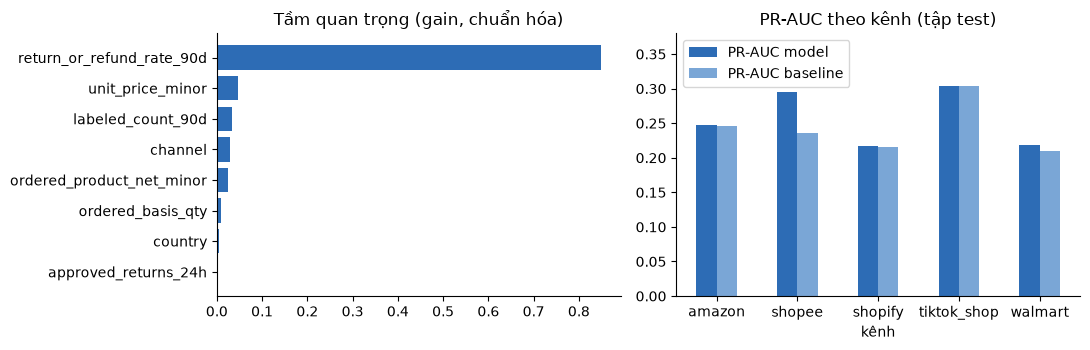

,dòng,tỷ lệ dương,PR-AUC model,PR-AUC baseline
kênh,,,,
amazon,11626,0.1116,0.2469,0.2458
shopee,373,0.0938,0.2946,0.2362
shopify,1081,0.0916,0.2167,0.2151
tiktok_shop,2266,0.1311,0.3040,0.3044
walmart,1065,0.1042,0.2183,0.2094


In [9]:
imp = pd.Series(model.booster_.feature_importance("gain"), index=FEATURES)
imp = (imp / imp.sum()).sort_values()
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
axes[0].barh(imp.index, imp.values, color="#2d6cb5")
axes[0].set_title("Tầm quan trọng (gain, chuẩn hóa)")
per = []
for ch in test["channel"].cat.categories:
    m = (test["channel"] == ch).to_numpy()
    if y[m].min() == y[m].max():
        continue
    per.append({"kênh": ch, "dòng": int(m.sum()), "tỷ lệ dương": y[m].mean(),
                "PR-AUC model": average_precision_score(y[m], model_scores[m]),
                "PR-AUC baseline": average_precision_score(y[m], base_scores[m])})
per = pd.DataFrame(per).set_index("kênh")
per[["PR-AUC model", "PR-AUC baseline"]].plot.bar(ax=axes[1], color=["#2d6cb5", "#7aa6d6"], rot=0)
axes[1].set_title("PR-AUC theo kênh (tập test)")
axes[1].set_ylim(0, 0.38)
plt.tight_layout()
plt.show()
per.round(4)

## Kết luận

In [10]:
point = mine["pr_auc_model"] - mine["pr_auc_baseline"]
print(f"- Tái lập: PR-AUC model {mine['pr_auc_model']:.4f} (MLflow {mlflow['pr_auc_model']:.4f}), baseline {mine['pr_auc_baseline']:.4f} (khớp tuyệt đối).")
print(f"- Chênh model - baseline: {point:+.4f}, bootstrap CI 95% [{lo:+.4f}, {hi:+.4f}], model > baseline ở {(diff > 0).mean():.0%} mẫu.")
print(f"- Qua 5 seed: model {seed_df['pr_auc_model'].min():.4f} .. {seed_df['pr_auc_model'].max():.4f}; baseline {mine['pr_auc_baseline']:.4f}.")

- Tái lập: PR-AUC model 0.2520 (MLflow 0.2520), baseline 0.2472 (khớp tuyệt đối).
- Chênh model - baseline: +0.0048, bootstrap CI 95% [-0.0003, +0.0099], model > baseline ở 96% mẫu.
- Qua 5 seed: model 0.2512 .. 0.2532; baseline 0.2472.


**Đọc kết quả (trung thực).**

- Model **tái lập chính xác** số của MLflow, nên con số 0,2520 so với 0,2472 là thật, không phải ngẫu nhiên của một lần chạy.
- Chênh lệch **+0,0048 nhưng khoảng tin cậy 95% bootstrap chạm 0** (`[-0,0003; +0,0099]`): model hơn baseline ở khoảng 96% mẫu, chưa đạt ngưỡng 97,5% của kiểm định hai phía. Có thể nói model **có xu hướng** hơn baseline, **chưa thể khẳng định** một cách chắc chắn.
- Cả 5 seed đều hơn baseline (độ lệch chuẩn giữa seed 0,0008, nhỏ hơn chênh lệch 0,0048), nên chênh lệch không đến từ may rủi của seed, nhưng là một việc khác với may rủi của tập test.
- Bootstrap lấy lại từng dòng như độc lập; thực tế các dòng cùng SKU/đơn có tương quan, nên khoảng tin cậy thật có thể **rộng hơn** khoảng ở trên.
- Theo kênh, model chỉ rõ ràng hơn ở `shopee` (373 dòng, chỉ khoảng 35 dòng dương, rất nhiễu) và ngang hoặc kém baseline ở `tiktok_shop`; kênh `amazon` (71% test) gần như hòa. Lợi thế theo kênh không đồng đều.
- Khoảng 85% tầm quan trọng (gain) nằm ở `return_or_refund_rate_90d`, chính là cột mà baseline dùng: model chủ yếu học lại baseline và chỉ thêm một phần nhỏ từ giá, kênh, số lượng.
- Đòn bẩy lớn hơn nằm ở dữ liệu chứ không ở mô hình: `approved_returns_24h` rỗng 100% lúc train nên model chưa dùng được feature tươi nhất.

Luật "thắng baseline thì đặt production" của pipeline vẫn đúng (điểm số hơn), nhưng bằng chứng thống kê cho việc model **tốt hơn rule đơn giản** còn yếu.